# Armonización satelital MODIS + VIIRS para monitoreo de incendios — Parque Nacional Tunari y municipio de Cochabamba

**Notebook único del proyecto.** Reúne el recorrido completo y, al final, una tabla de **qué se verificó y cómo**.

Cómo leerlo:
1. Cada sección explica una decisión, muestra los resultados ya calculados y **ejecuta comprobaciones** (`✔ OK` / `✘ FALLA`).
2. La sección 13 junta todas las comprobaciones en una sola tabla. Si alguna falla, el notebook termina con error.
3. No recalcula lo pesado: lee los resultados (`DATOS_PROCESADOS/`), el paquete para el backend (`entrega_backend/`) y la copia de «antes» de la regla (`VERIFICACION_REGLA_DISTRITOS/`).

| Sección | Tema |
|---|---|
| 1–4 | Datos, filtro, día de Bolivia, celda-día, grilla |
| 5 | Armonización MODIS↔VIIRS (factor 2,87) y su error |
| 6 | Índice por área y regla (solo el Tunari es mixto) |
| 7 | Alertas |
| 8–9 | Distritos y puntos calientes (Gi\*) |
| 10 | Pruebas de robustez |
| 11 | Compatibilidad con el backend de TunariGuard |
| 12 | Verificación del pipeline original |
| 13 | **Qué se verificó (tabla completa)** |
| 14–15 | Limitaciones y cómo actualizar |

> Una detección satelital **no es un incendio confirmado**: es un píxel con calor anómalo visto por un satélite.

In [1]:
import os, sys, re, subprocess, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd()
PAQ = ROOT / "entrega_backend" / "datos"
SER = ROOT / "DATOS_PROCESADOS" / "series"
FIG = ROOT / "DATOS_PROCESADOS" / "figuras"
BASE = ROOT / "VERIFICACION_REGLA_DISTRITOS" / "base_antes_de_la_regla"
PRU = ROOT / "VERIFICACION_REGLA_DISTRITOS" / "pruebas"
sys.path.insert(0, str(ROOT))
import regla_indice_areas as RI

VERIF = []   # tabla de verificaciones: se llena con verificar(...) y se muestra en la sección 13

def verificar(seccion, que, como, ok, detalle=""):
    ok = bool(ok)
    VERIF.append({"sección": seccion, "qué se verifica": que, "cómo": como, "resultado": "OK" if ok else "FALLA", "detalle": str(detalle)})
    print(("✔ OK    " if ok else "✘ FALLA ") + que + (f"   [{detalle}]" if detalle else ""))

def figura(nombre, ancho=900):
    display(Image(filename=str(FIG / nombre), width=ancho))

def correr(*args):
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}
    return subprocess.run([sys.executable, *args], capture_output=True, text=True, encoding="utf-8", env=env, cwd=ROOT)

version = (ROOT / "entrega_backend" / "ESQUEMA_VERSION").read_text().strip()
print("Paquete para el backend, versión del esquema:", version)

Paquete para el backend, versión del esquema: 2026.11.13-6


## 1. Datos: qué detecciones hay

Fuente: **NASA FIRMS** (detecciones activas de calor). Cuatro productos: MODIS (Terra y Aqua, 1 km, desde 2001) y VIIRS 375 m (Suomi-NPP desde 2012, NOAA-20 desde 2018, NOAA-21 en 2026).

- **Estándar** (`estandar`): dato definitivo de NASA (llega meses después).
- **NRT** (casi tiempo real): provisional, sin la columna `type`; se reemplaza después **por rango de fechas**.

La tabla es la del paquete (`detecciones.csv`): solo lo que cae **dentro** del Parque Tunari o del municipio de Cochabamba.

In [2]:
det = pd.read_csv(PAQ / "detecciones.csv")
resumen = det.groupby("fuente").agg(detecciones=("id_deteccion", "size"), primera=("fecha_bo", "min"), ultima=("fecha_bo", "max"),
                                    NRT=("origen_dato", lambda s: int((s == "NRT").sum())))
display(resumen)
print("Total de detecciones:", len(det), "| en el parque:", int(det.en_parque_tunari.sum()), "| en el municipio:", int(det.en_municipio_cochabamba.sum()))

verificar("1 Datos", "id_deteccion es único", "len(unique) == len(filas)", det.id_deteccion.is_unique, len(det))
verificar("1 Datos", "la cobertura termina el 2026-10-31 (último mes completo con Suomi-NPP)", "max(fecha_bo) <= 2026-10-31", det.fecha_bo.max() <= "2026-10-31", det.fecha_bo.max())

,detecciones,primera,ultima,NRT
fuente,,,,
MODIS-Aqua,574,2002-09-23,2026-10-19,12
MODIS-Terra,266,2001-08-09,2026-10-17,6
VIIRS-NOAA-20,2112,2018-04-05,2026-10-30,176
VIIRS-NOAA-21,223,2026-03-01,2026-10-31,131
VIIRS-Suomi-NPP,2982,2012-05-20,2026-10-29,142


Total de detecciones: 6157 | en el parque: 5646 | en el municipio: 680
✔ OK    id_deteccion es único   [6157]
✔ OK    la cobertura termina el 2026-10-31 (último mes completo con Suomi-NPP)   [2026-10-31]


## 2. Filtro común

Se conservan solo detecciones de **tipo 0** (presunto fuego de vegetación) con **confianza distinta de «baja»**. Es el filtro principal del análisis.
(Los NRT públicos no traen el tipo: se asume 0 y se marcan con `tipo_conocido = false`.)

In [3]:
display(pd.crosstab(det.fuente, det.confianza_clase))
display(det.groupby(["origen_dato", "tipo_conocido"]).size().rename("filas").to_frame())

verificar("2 Filtro", "todas las filas son tipo 0", "det.tipo == 0", (det.tipo == 0).all())
verificar("2 Filtro", "ninguna fila tiene confianza «baja»", "confianza_clase ∈ {nominal, alta}", det.confianza_clase.isin(["nominal", "alta"]).all())
verificar("2 Filtro", "solo las filas NRT tienen tipo desconocido", "tipo_conocido == False ⇔ origen_dato == NRT", ((~det.tipo_conocido) == (det.origen_dato == "NRT")).all())

confianza_clase,alta,nominal
fuente,,
MODIS-Aqua,120,454
MODIS-Terra,53,213
VIIRS-NOAA-20,200,1912
VIIRS-NOAA-21,18,205
VIIRS-Suomi-NPP,259,2723


,,filas
origen_dato,tipo_conocido,
NRT,False,467
estandar,True,5690


✔ OK    todas las filas son tipo 0
✔ OK    ninguna fila tiene confianza «baja»
✔ OK    solo las filas NRT tienen tipo desconocido


## 3. Día de Bolivia y celda-día

- **Día de Bolivia:** UTC−4. FIRMS reporta en UTC; una detección a las 02:00 UTC del 5 de marzo es del 4 de marzo en Bolivia. Los conteos por día y mes usan `fecha_bo`.
- **Celda-día:** una celda de 1 km (cuadrícula UTM 20S) con **al menos una detección** ese día. Evita contar dos veces el mismo fuego visto por dos satélites o por varios píxeles.

In [4]:
utc = pd.to_datetime(det.fecha_hora_utc)
bo = (utc - pd.Timedelta(hours=4)).dt.strftime("%Y-%m-%d")
verificar("3 Día", "fecha_bo = fecha UTC − 4 horas en todas las filas", "recalculo de (UTC − 4 h).fecha", (bo == det.fecha_bo).all(), f"{int((bo != det.fecha_bo).sum())} difieren")

ejemplo = det.loc[(utc.dt.hour < 4), ["fecha_hora_utc", "fecha_hora_bo", "fecha_bo", "fuente"]].head(4)
display(ejemplo)

v = det[(det.fuente == "VIIRS-Suomi-NPP") & det.en_parque_tunari & det.fecha_bo.between("2013-01-01", "2025-12-31")]
print(f"Parque, Suomi-NPP 2013-2025: {len(v)} filas -> {v.drop_duplicates(['cell_id', 'fecha_bo']).shape[0]} celdas-día (las filas repiten celdas el mismo día)")

✔ OK    fecha_bo = fecha UTC − 4 horas en todas las filas   [0 difieren]


,fecha_hora_utc,fecha_hora_bo,fecha_bo,fuente
0,2001-08-10 03:06:00,2001-08-09 23:06:00,2001-08-09,MODIS-Terra
1,2001-08-10 03:06:00,2001-08-09 23:06:00,2001-08-09,MODIS-Terra
5,2002-08-03 02:23:00,2002-08-02 22:23:00,2002-08-02,MODIS-Terra
57,2004-08-06 02:33:00,2004-08-05 22:33:00,2004-08-05,MODIS-Terra


Parque, Suomi-NPP 2013-2025: 2452 filas -> 1683 celdas-día (las filas repiten celdas el mismo día)


## 4. Grilla de 1 km

Todas las áreas comparten una grilla común de celdas de 1 km. Cada detección cae en una celda; la tabla `celdas_1km` contiene toda la grilla del parque y del municipio (no solo celdas con detecciones).

In [5]:
celdas = pd.read_csv(PAQ / "celdas_1km.csv", usecols=["cell_id"])
esperados = pd.read_json(ROOT / "entrega_backend" / "conteos_esperados.json", typ="series")
reales = {f.stem: len(pd.read_csv(f)) for f in sorted(PAQ.glob("*.csv"))}
cmp = pd.DataFrame({"esperado": esperados, "real": pd.Series(reales)})
display(cmp.T)

verificar("4 Grilla", "toda detección cae en una celda registrada", "det.cell_id ⊂ celdas_1km.cell_id", det.cell_id.isin(set(celdas.cell_id)).all())
verificar("4 Grilla", "los 17 CSV del paquete tienen el número de filas esperado", "conteos_esperados.json == filas reales", (cmp.esperado == cmp.real).all(), f"{len(cmp)} tablas")
verificar("4 Grilla", "la versión del esquema es 2026.11.13-6", "ESQUEMA_VERSION", version == "2026.11.13-6", version)

,alerta_mes_en_curso,alertas_mensuales,areas,casos_documentados,celdas_1km,conglomerados_gi,detecciones,detecciones_area,eventos,factores_satelites,fuentes_satelitales,parametros,puntos_calientes_gi,recurrencia_celda,serie_agregada,serie_mensual,tendencias
esperado,48,5207,31,7,3791,20,6157,393,2577,16,5,30,4138,2014,128,9519,5
real,48,5207,31,7,3791,20,6157,393,2577,16,5,30,4138,2014,128,9519,5


✔ OK    toda detección cae en una celda registrada
✔ OK    los 17 CSV del paquete tienen el número de filas esperado   [17 tablas]
✔ OK    la versión del esquema es 2026.11.13-6   [2026.11.13-6]


## 5. Armonización MODIS ↔ VIIRS

Para comparar 2001–2011 (solo MODIS) con 2012 en adelante (también VIIRS) hay que convertir VIIRS a «unidades MODIS». El **factor** `f` dice cuántas celdas-día de VIIRS equivalen a una de MODIS: **f = 2,8715** (media geométrica / regresión por eje mayor, Tunari, 2013–2025). Se evalúa **fuera de muestra**: se ajusta con 2013–2021 y se predice MODIS de 2022–2025 a partir de VIIRS.

Error esperado (declarado en los documentos): ≈ **40 % mensual, 27 % trimestral, 16 % anual**. El error mensual es alto porque MODIS casi no registra nada cada mes en el parque; por eso se reporta a escala trimestral o anual.

Factor operativo f = 2.8715  | rango estructural 2.71 – 3.37  | periodo de ajuste 2013-2025


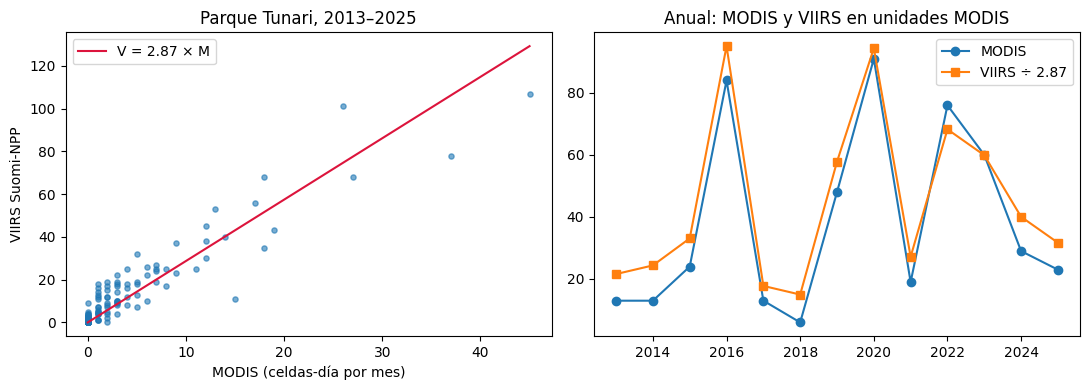

Factor ajustado solo con 2013–2021: 3.031
Error fuera de muestra 2022–2025 (WAPE): mensual 40.5 %  | trimestral 27.0 %  | anual 16.3 %
✔ OK    el factor operativo es 2,8715   [2.8715]
✔ OK    el factor usado en el paquete es el mismo
✔ OK    error mensual fuera de muestra ≈ 40 % (35–45 %)   [40.5 %]
✔ OK    error anual fuera de muestra ≈ 16 % (10–22 %)   [16.3 %]


In [6]:
fac = pd.read_csv(SER / "tunari_factores_calibracion.csv").iloc[0]
f = float(fac.factor_viirs_por_modis)
print(f"Factor operativo f = {f:.4f}  | rango estructural {fac.factor_estructural_minimo:.2f} – {fac.factor_estructural_maximo:.2f}  | periodo de ajuste {fac.periodo_ajuste_final}")

sm = pd.read_csv(PAQ / "serie_mensual.csv", parse_dates=["mes"])
t = sm[(sm.area_id == "parque-tunari") & sm.mes.between("2013-01-01", "2025-12-01")].set_index("mes")
M, V = t.modis_celdas_dia, t.viirs_snpp_celdas_dia

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(M, V, s=14, alpha=.6)
xs = np.linspace(0, M.max(), 50)
ax[0].plot(xs, f * xs, color="crimson", label=f"V = {f:.2f} × M")
ax[0].set_xlabel("MODIS (celdas-día por mes)"); ax[0].set_ylabel("VIIRS Suomi-NPP"); ax[0].set_title("Parque Tunari, 2013–2025"); ax[0].legend()
anual = t.groupby(t.index.year)[["modis_celdas_dia", "viirs_snpp_celdas_dia"]].sum()
ax[1].plot(anual.index, anual.modis_celdas_dia, marker="o", label="MODIS")
ax[1].plot(anual.index, anual.viirs_snpp_celdas_dia / f, marker="s", label=f"VIIRS ÷ {f:.2f}")
ax[1].set_title("Anual: MODIS y VIIRS en unidades MODIS"); ax[1].legend()
plt.tight_layout(); plt.show()

# evaluación fuera de muestra: factor con 2013-2021, predicción de MODIS 2022-2025
tr, te = t[t.index.year <= 2021], t[t.index.year >= 2022]
f_tr = np.sqrt((tr.viirs_snpp_celdas_dia ** 2).sum() / (tr.modis_celdas_dia ** 2).sum())
def wape(real, pred): return 100 * np.abs(real - pred).sum() / real.sum()
pred = te.viirs_snpp_celdas_dia / f_tr
w_m = wape(te.modis_celdas_dia, pred)
w_t = wape(te.modis_celdas_dia.resample("QS").sum(), pred.resample("QS").sum())
w_a = wape(te.modis_celdas_dia.groupby(te.index.year).sum(), pred.groupby(pred.index.year).sum())
print(f"Factor ajustado solo con 2013–2021: {f_tr:.3f}")
print(f"Error fuera de muestra 2022–2025 (WAPE): mensual {w_m:.1f} %  | trimestral {w_t:.1f} %  | anual {w_a:.1f} %")

verificar("5 Armonización", "el factor operativo es 2,8715", "tunari_factores_calibracion.csv", abs(f - 2.8715) < 1e-3, round(f, 4))
verificar("5 Armonización", "el factor usado en el paquete es el mismo", "serie_mensual.factor_viirs_por_modis (Tunari)", abs(float(t.factor_viirs_por_modis.iloc[0]) - f) < 1e-9)
verificar("5 Armonización", "error mensual fuera de muestra ≈ 40 % (35–45 %)", "WAPE 2022-2025, factor ajustado con 2013-2021", 35 <= w_m <= 45, f"{w_m:.1f} %")
verificar("5 Armonización", "error anual fuera de muestra ≈ 16 % (10–22 %)", "WAPE anual 2022-2025", 10 <= w_a <= 22, f"{w_a:.1f} %")

## 6. Índice por área y regla

**Índice del Tunari (único calibrado):** antes de febrero de 2012 = MODIS; desde febrero de 2012 = (MODIS + VIIRS/f) / 2.

**Fuera del Tunari** MODIS casi no registra nada (en 2013–2025 el municipio tiene 32 celdas-día de MODIS frente a 251 de VIIRS; **nueve de los 15 distritos tienen cero**), y el factor propio de otras áreas no es estable. Por eso:

| Área | Método | Índice | Calidad |
|---|---|---|---|
| Parque Tunari | `mixto_calibrado` | (MODIS + VIIRS/f)/2 | `calibrado_localmente_en_tunari` |
| Cualquier otra área, desde feb-2012 | `viirs_reescalado` | VIIRS / 2,8715 | `aproximado_factor_transferido` |
| Cualquier otra área, antes de feb-2012 | `viirs_reescalado` | sin valor (NULL) | `no_comparable` |

El rango VIIRS/3,37 – VIIRS/2,09 es un **rango de sensibilidad al factor**, no un intervalo de confianza. Un valor casi nulo antes de 2012 **no permite distinguir** entre ausencia de fuego y falta de detección de MODIS.

,,,,áreas
metodo_indice,origen_factor,validacion_local,comparabilidad_pre_2012,
mixto_calibrado,calibrado_en_tunari,calibrada,comparable,1
viirs_reescalado,transferido_desde_tunari,no_disponible,no_comparable,30


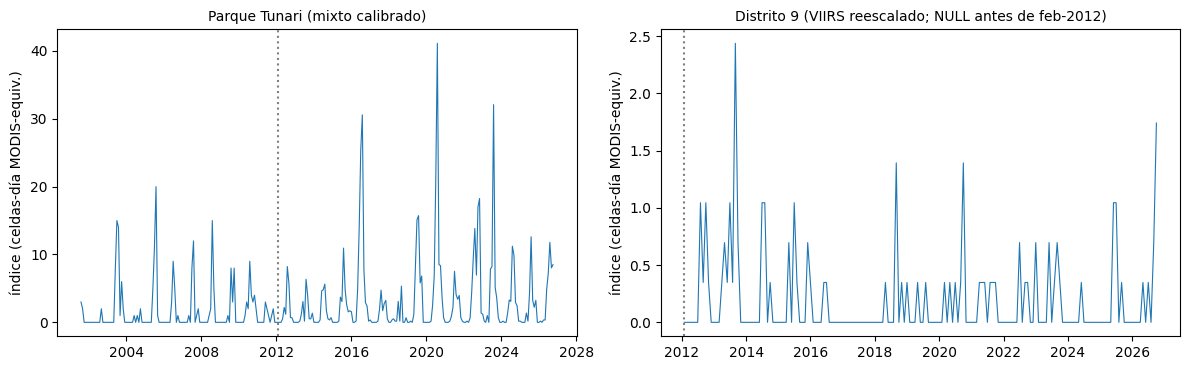

✔ OK    solo el Parque Tunari es mixto_calibrado (1 área); las otras 30 son viirs_reescalado   [{'viirs_reescalado': 30, 'mixto_calibrado': 1}]
✔ OK    antes de feb-2012 el índice es NULL y la calidad no_comparable (áreas viirs_reescalado)   [3906 meses]
✔ OK    desde feb-2012 el índice es VIIRS / f   [5310 meses]
✔ OK    el rango de sensibilidad está ordenado (VIIRS/3,37 ≤ índice ≤ VIIRS/2,09)
✔ OK    el Tunari es el único con calidad calibrado_localmente_en_tunari
✔ OK    los 12 municipios del parque se muestran como «Sector del Tunari en …» y su alcance es solo el sector   [12]


In [7]:
areas = pd.read_csv(PAQ / "areas.csv", usecols=["area_id", "tipo", "nombre_visible", "alcance_estadistico", "metodo_indice", "origen_factor", "validacion_local", "comparabilidad_pre_2012"])
display(areas.groupby(["metodo_indice", "origen_factor", "validacion_local", "comparabilidad_pre_2012"]).size().rename("áreas").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_id, eje, tit in (("parque-tunari", ax[0], "Parque Tunari (mixto calibrado)"), ("distrito-09", ax[1], "Distrito 9 (VIIRS reescalado; NULL antes de feb-2012)")):
    s = sm[sm.area_id == a_id].set_index("mes")
    eje.plot(s.index, s.indice_modis_equivalente, lw=.8)
    eje.axvline(pd.Timestamp("2012-02-01"), color="gray", ls=":")
    eje.set_title(tit, fontsize=10); eje.set_ylabel("índice (celdas-día MODIS-equiv.)")
plt.tight_layout(); plt.show()

# comprobaciones de la regla (la misma lógica de verificar_regla_areas.py, aquí en vivo)
sv = sm.merge(areas[["area_id", "metodo_indice"]], on="area_id")
solo = sv[sv.metodo_indice == RI.METODO_SOLO_VIIRS]
pre, post = solo[solo.mes < "2012-02-01"], solo[solo.mes >= "2012-02-01"]
verificar("6 Regla", "solo el Parque Tunari es mixto_calibrado (1 área); las otras 30 son viirs_reescalado", "areas.metodo_indice", (areas.metodo_indice == RI.METODO_MIXTO).sum() == 1 and areas.loc[areas.metodo_indice == RI.METODO_MIXTO, "area_id"].iloc[0] == "parque-tunari", dict(areas.metodo_indice.value_counts()))
verificar("6 Regla", "antes de feb-2012 el índice es NULL y la calidad no_comparable (áreas viirs_reescalado)", "pre.indice.isna() y calidad", pre.indice_modis_equivalente.isna().all() and (pre.calidad_indice == RI.CAL_NO_COMPARABLE).all(), f"{len(pre)} meses")
verificar("6 Regla", "desde feb-2012 el índice es VIIRS / f", "np.allclose(indice, viirs / f)", np.allclose(post.indice_modis_equivalente, post.viirs_snpp_celdas_dia / post.factor_viirs_por_modis), f"{len(post)} meses")
verificar("6 Regla", "el rango de sensibilidad está ordenado (VIIRS/3,37 ≤ índice ≤ VIIRS/2,09)", "limite_inferior ≤ indice ≤ limite_superior", ((post.limite_inferior_estructural <= post.indice_modis_equivalente + 1e-9) & (post.indice_modis_equivalente <= post.limite_superior_estructural + 1e-9)).all())
verificar("6 Regla", "el Tunari es el único con calidad calibrado_localmente_en_tunari", "calidad_indice", set(sv[sv.calidad_indice == RI.CAL_CALIBRADO].area_id) == {"parque-tunari"})

mp = areas[areas.tipo == "municipio_parque"]
verificar("6 Regla", "los 12 municipios del parque se muestran como «Sector del Tunari en …» y su alcance es solo el sector", "nombre_visible / alcance_estadistico", mp.nombre_visible.str.startswith("Sector del Tunari en ").all() and (mp.alcance_estadistico == "solo_sector_del_parque").all(), len(mp))

### Comparación con la copia de «antes» de la regla

Se guardó una copia de los CSV de antes de aplicar la regla (con sus huellas SHA-256 en `VERIFICACION_REGLA_DISTRITOS/`). Se comprueba que **el Tunari, los conteos y la serie agregada no cambiaron**; lo único que cambia son los índices de las demás áreas y 4 niveles de alerta (ver sección 7).

In [8]:
ant = pd.read_csv(BASE / "serie_mensual.csv")
cur = pd.read_csv(PAQ / "serie_mensual.csv")
pa, pn = ant[ant.area_id == "parque-tunari"].reset_index(drop=True), cur[cur.area_id == "parque-tunari"].reset_index(drop=True)
col_t = list(pa.columns)
ig_t = all((np.allclose(pa[c].astype(float), pn[c].astype(float), equal_nan=True) if pa[c].dtype.kind in "fi" else (pa[c].astype(str) == pn[c].astype(str)).all()) for c in col_t)
verificar("6 Regla", "el Parque Tunari es idéntico a antes de la regla (todas las columnas originales)", "comparación columna a columna con la copia de antes", ig_t, f"{len(pa)} meses, {len(col_t)} columnas")

ag_a, ag_n = pd.read_csv(BASE / "serie_agregada.csv"), pd.read_csv(PAQ / "serie_agregada.csv")
verificar("6 Regla", "la serie agregada es idéntica", "comparación de texto", ag_a.fillna("§").astype(str).equals(ag_n.fillna("§").astype(str)))

mm = ant.merge(cur, on=["area_id", "mes"], suffixes=("_a", "_n"))
verificar("6 Regla", "conteos de MODIS/VIIRS, índice para alertas y base de alertas de las 31 áreas, sin cambios", "np.allclose en 4 columnas", all(np.allclose(mm[c + "_a"], mm[c + "_n"], equal_nan=True) for c in ("modis_celdas_dia", "viirs_snpp_celdas_dia", "indice_para_alertas", "conteo_base_alertas")), f"{mm.area_id.nunique()} áreas")

mm["a"] = mm.mes.str[:4].astype(int)
w = mm[mm.a.between(2013, 2025)].groupby("area_id").agg(antes=("indice_modis_equivalente_a", "sum"), ahora=("indice_modis_equivalente_n", "sum"))
w["cambio_%"] = 100 * (w.ahora - w.antes) / w.antes.replace(0, np.nan)
display(w.sort_values("cambio_%").round(1))

✔ OK    el Parque Tunari es idéntico a antes de la regla (todas las columnas originales)   [303 meses, 15 columnas]
✔ OK    la serie agregada es idéntica
✔ OK    conteos de MODIS/VIIRS, índice para alertas y base de alertas de las 31 áreas, sin cambios   [31 áreas]


,antes,ahora,cambio_%
area_id,,,
distrito-11,0.500,0.000,-100.000
mun-ayopaya,7.800,5.600,-28.400
distrito-01,0.800,0.700,-17.900
mun-tapacari,17.900,16.700,-6.400
mun-morochata,121.100,115.300,-4.800
parque-tunari,542.600,542.600,0.000
mun-colomi,42.300,43.500,3.000
mun-sacaba,110.300,115.600,4.800
mun-cocapata,37.700,41.400,9.900


## 7. Alertas

**Qué usan exactamente:**
- **Antes de febrero de 2012**, las alertas históricas usan **MODIS** (mínimo de actividad: 2 celdas-día).
- **Desde febrero de 2012**, la probabilidad de exceso y el mínimo de actividad usan **conteos de VIIRS Suomi-NPP**. No emplean el índice mixto ni el factor.
- Modelo: **binomial negativa estacional**, prospectiva (cada año se ajusta solo con años anteriores de su misma era), mínimo 5 años de historial. Niveles por probabilidad de exceso: *elevada* p ≤ 0,10 · *alta* p ≤ 0,05 · *muy alta* p ≤ 0,01.
- **Mínimo de actividad en conteos:** ≥ 6 celdas-día de VIIRS (equivale exactamente a VIIRS/2,8715 ≥ 2). Se fijó en conteos para que un reajuste futuro del factor no cambie retroactivamente ningún nivel: con factor 2,09 serían 98 alertas, con 2,87 son 89 y con 3,37 serían 75.

**Corrección de la versión -6:** hasta la -5, distritos, municipio y áreas extra aplicaban el filtro sobre el índice mixto (con MODIS). Se unificó: 4 meses de octubre de 2019 pasan de «normal» a «alta/muy alta» (áreas superpuestas, probablemente un mismo episodio); el conjunto base pasa de 86 a 89 alertas.

nivel_alerta,normal,sin_baseline,alta,elevada,muy_alta
meses,2698,1800,39,27,23


Alertas del conjunto base (elevada + alta + muy_alta): 89
✔ OK    toda fila con alerta tiene p ≤ 0,10 y supera el mínimo de actividad   [97]
✔ OK    cada nivel respeta su umbral (0,10 / 0,05 / 0,01)
✔ OK    las probabilidades están entre 0 y 1
✔ OK    mínimo de actividad en conteos: VIIRS ≥ 6 desde 2012, MODIS ≥ 2 antes
✔ OK    ese 6 equivale a VIIRS / 2,8715 ≥ 2
✔ OK    conjunto base: 89 alertas históricas   [89]
✔ OK    mismas filas, conteos y probabilidades que antes de la corrección   [5207 filas]


,area_id,variante,mes,nivel_alerta_a,nivel_alerta_n,probabilidad_exceso_n
528,distrito-13,base,2019-10-01,normal,muy_alta,0.000
1458,municipio-cochabamba,base,2019-10-01,normal,alta,0.017
1768,municipio-cochabamba,sin_fuentes_persistentes,2019-10-01,normal,muy_alta,0.006
5122,zona-cota-2750,base,2019-10-01,normal,muy_alta,0.000


✔ OK    solo 4 filas cambian de nivel (todas «normal» antes, octubre de 2019)   [4]
✔ OK    el Tunari y los municipios del parque no cambian ni una fila   [2727]


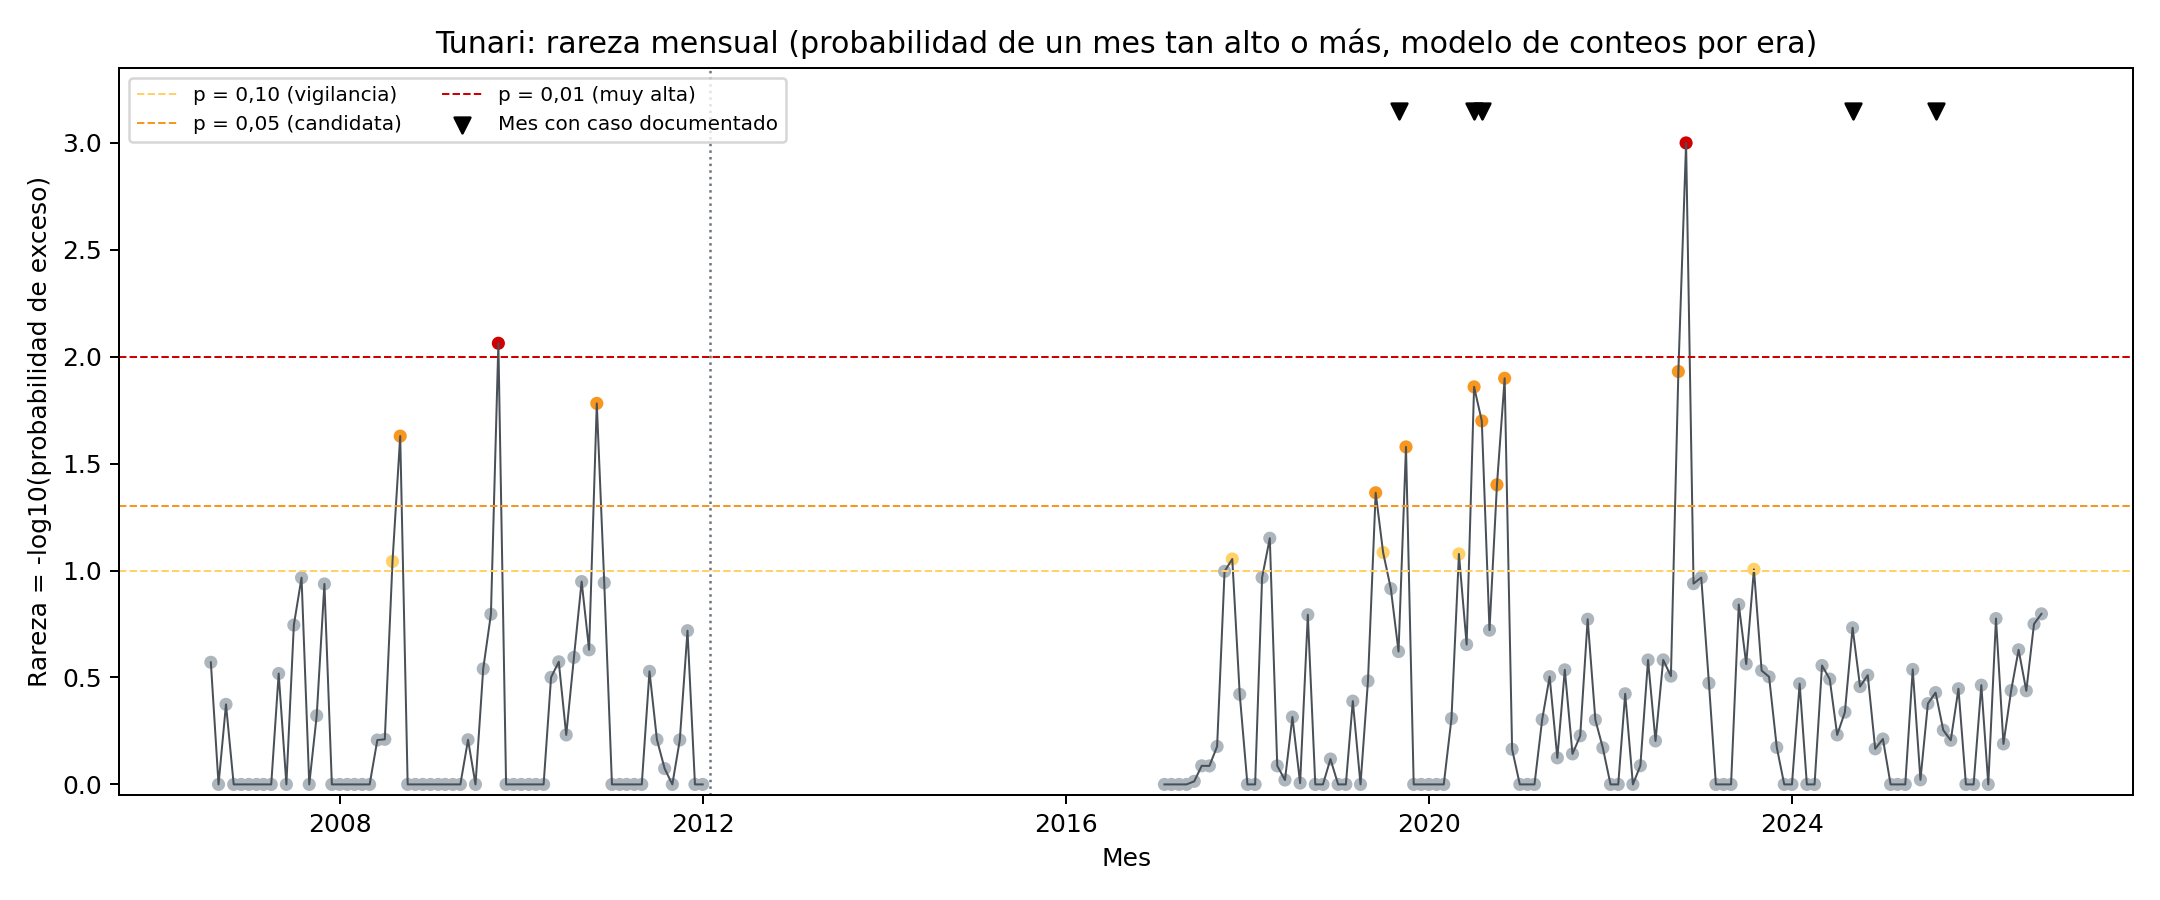

In [9]:
al = pd.read_csv(PAQ / "alertas_mensuales.csv")
ba = al[al.variante == "base"]
display(ba.nivel_alerta.value_counts().rename("meses").to_frame().T)
alertas_base = int(ba.nivel_alerta.isin(["elevada", "alta", "muy_alta"]).sum())
print("Alertas del conjunto base (elevada + alta + muy_alta):", alertas_base)

# 1) el nivel sale de la probabilidad y del mínimo de actividad
con_alerta = al[al.nivel_alerta.isin(["elevada", "alta", "muy_alta"])]
verificar("7 Alertas", "toda fila con alerta tiene p ≤ 0,10 y supera el mínimo de actividad", "nivel ∈ {elevada, alta, muy_alta} ⇒ p ≤ 0,10 y actividad_minima_ok", ((con_alerta.probabilidad_exceso <= 0.10) & con_alerta.actividad_minima_ok.astype(bool)).all(), len(con_alerta))
lim = {"elevada": 0.10, "alta": 0.05, "muy_alta": 0.01}
nivel_ok = all((con_alerta[con_alerta.nivel_alerta == n].probabilidad_exceso <= p).all() for n, p in lim.items())
verificar("7 Alertas", "cada nivel respeta su umbral (0,10 / 0,05 / 0,01)", "p ≤ umbral del nivel", nivel_ok)
verificar("7 Alertas", "las probabilidades están entre 0 y 1", "min ≥ 0 y max ≤ 1", al.probabilidad_exceso.dropna().between(0, 1).all())

# 2) el mínimo de actividad está en conteos
era_v = al.base_alertas.str.startswith("VIIRS")
esperado_ok = al.celdas_dia_base >= pd.Series(np.where(era_v, 6, 2), index=al.index)
verificar("7 Alertas", "mínimo de actividad en conteos: VIIRS ≥ 6 desde 2012, MODIS ≥ 2 antes", "actividad_minima_ok == (celdas_dia_base ≥ 6 ó 2)", (al.actividad_minima_ok.astype(bool) == esperado_ok).all())
verificar("7 Alertas", "ese 6 equivale a VIIRS / 2,8715 ≥ 2", "(c ≥ 6) == (c / f ≥ 2) para todo c observado", ((al[era_v].celdas_dia_base >= 6) == (al[era_v].celdas_dia_base / f >= 2)).all())
verificar("7 Alertas", "conjunto base: 89 alertas históricas", "conteo", alertas_base == 89, alertas_base)

# 3) comparación con la copia de antes: probabilidades y conteos idénticos, solo 4 filas cambian de nivel
al_a = pd.read_csv(BASE / "alertas_mensuales.csv")
k = ["area_id", "variante", "mes"]
m2 = al_a.merge(al, on=k, suffixes=("_a", "_n"))
verificar("7 Alertas", "mismas filas, conteos y probabilidades que antes de la corrección", "merge por (área, variante, mes)", len(m2) == len(al_a) == len(al) and ((m2.probabilidad_exceso_a.fillna(-1) - m2.probabilidad_exceso_n.fillna(-1)).abs() < 1e-12).all() and (m2.celdas_dia_base_a == m2.celdas_dia_base_n).all(), f"{len(al)} filas")
dif = m2[m2.nivel_alerta_a != m2.nivel_alerta_n]
display(dif[k + ["nivel_alerta_a", "nivel_alerta_n", "probabilidad_exceso_n"]])
verificar("7 Alertas", "solo 4 filas cambian de nivel (todas «normal» antes, octubre de 2019)", "diferencias de nivel", len(dif) == 4 and (dif.nivel_alerta_a == "normal").all() and (dif.mes == "2019-10-01").all(), len(dif))
propios = m2.area_id.eq("parque-tunari") | (m2.area_id.str.startswith("mun-") & ~m2.area_id.eq("municipio-cochabamba"))
verificar("7 Alertas", "el Tunari y los municipios del parque no cambian ni una fila", "nivel idéntico", (m2[propios].nivel_alerta_a == m2[propios].nivel_alerta_n).all(), int(propios.sum()))

figura("tunari_anomalias_y_alertas.png", 950)

## 8. Distritos y municipio de Cochabamba

El municipio tiene 15 distritos (**no 16**). Entre 2013 y 2025, MODIS ve muy poco en ellos (nueve distritos con cero celdas-día), así que el índice es VIIRS reescalado y antes de 2012 no hay valor comparable.

,modis_celdas_dia,viirs_snpp_celdas_dia
area_id,,
distrito-01,1,2
distrito-02,0,2
distrito-03,0,2
distrito-04,0,14
distrito-05,0,5
distrito-06,0,4
distrito-07,0,10
distrito-08,2,39
distrito-09,13,78


✔ OK    hay 15 distritos (no 16)   [15]
✔ OK    nueve distritos tienen 0 celdas-día de MODIS en 2013–2025   [9]
✔ OK    el municipio tiene 32 celdas-día de MODIS y 251 de VIIRS en 2013–2025


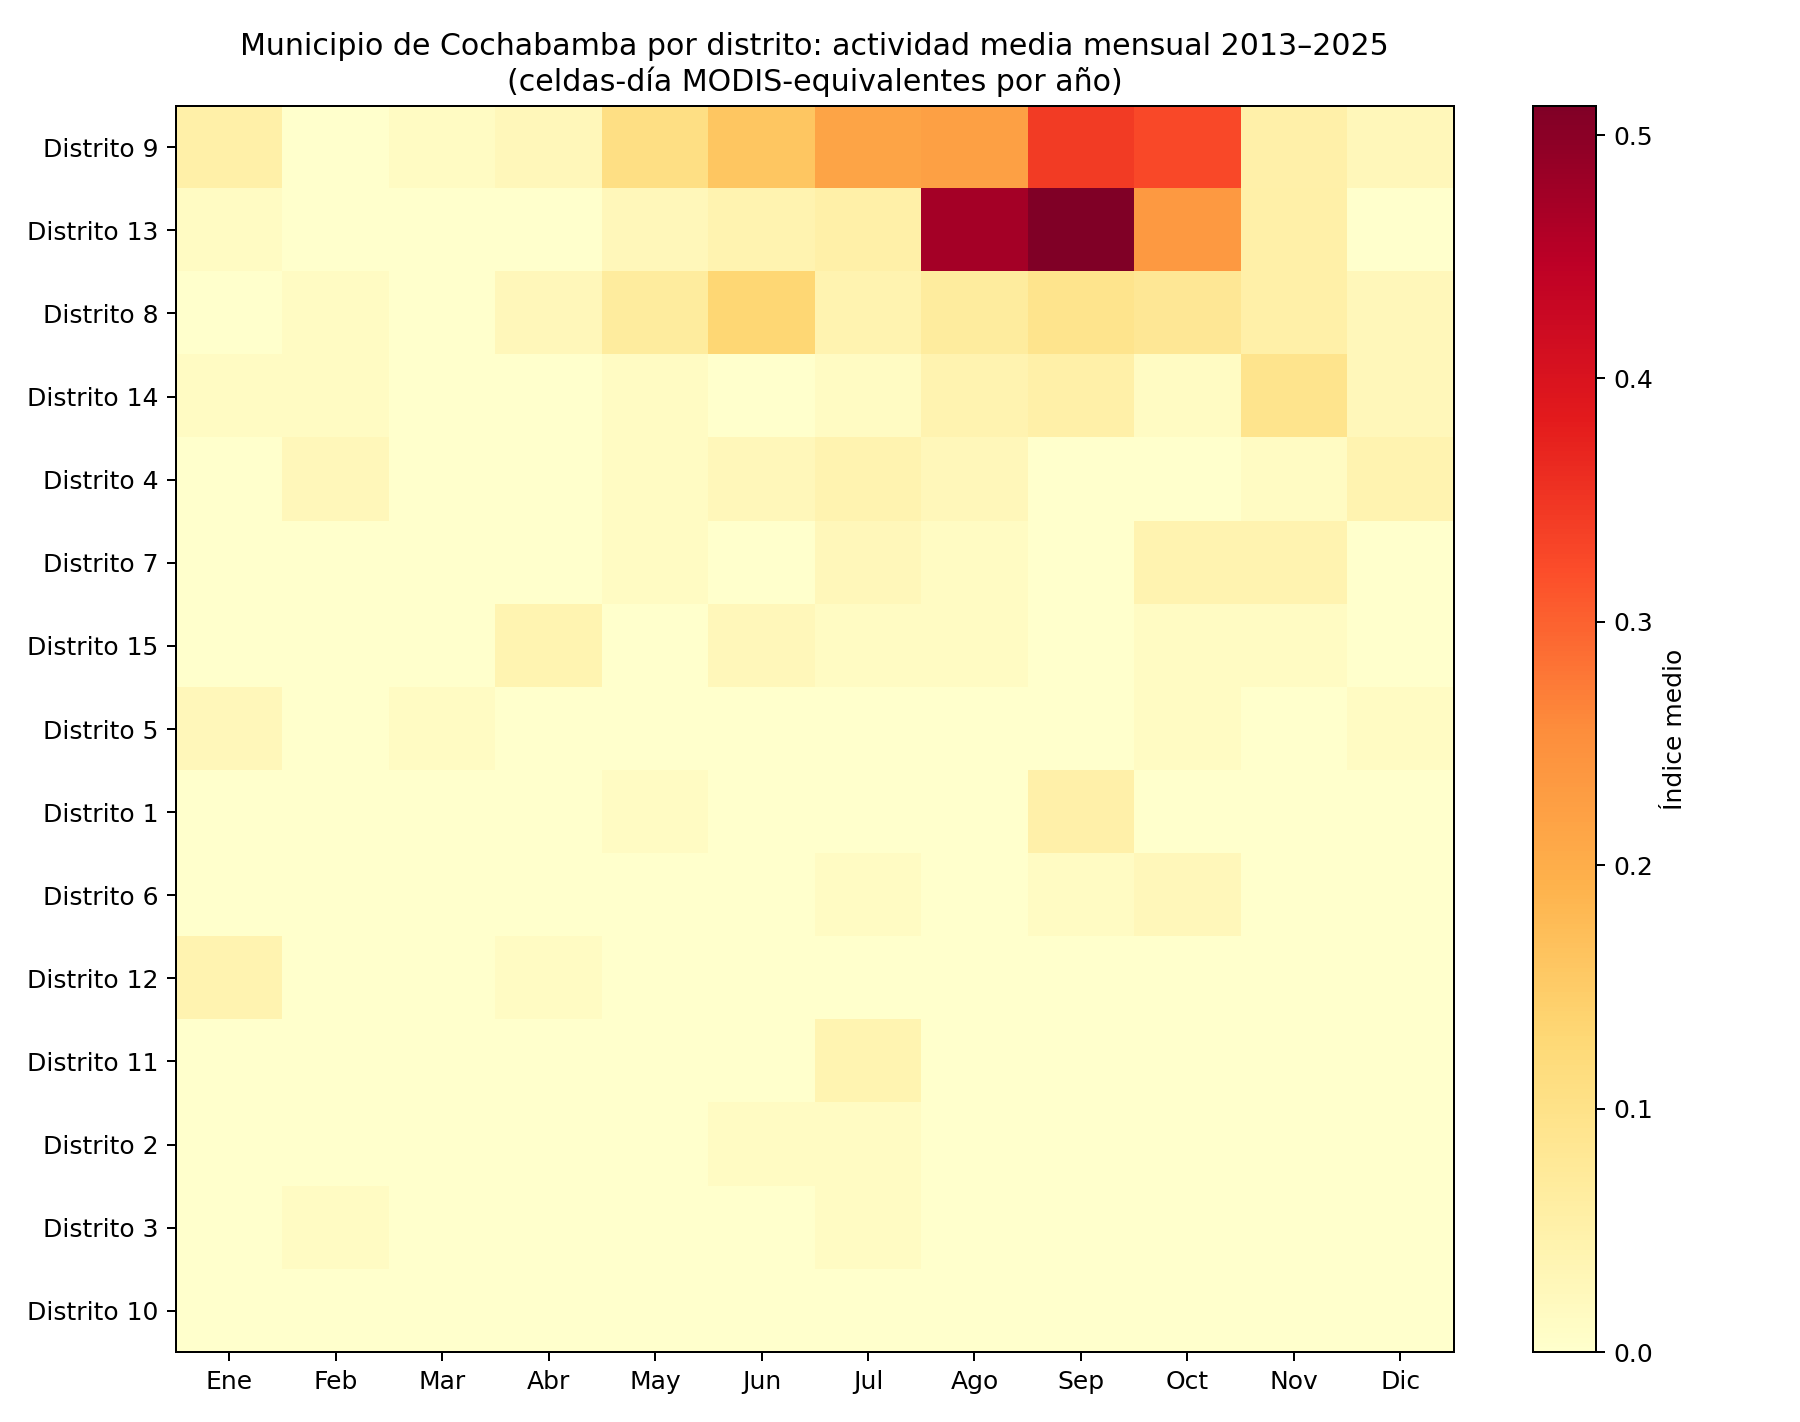

In [10]:
w2 = sm[sm.mes.between("2013-01-01", "2025-12-01") & sm.area_id.str.startswith(("distrito-", "municipio-cochabamba"))].groupby("area_id")[["modis_celdas_dia", "viirs_snpp_celdas_dia"]].sum()
display(w2.astype(int))
dist = w2[w2.index.str.startswith("distrito-")]
verificar("8 Distritos", "hay 15 distritos (no 16)", "areas.tipo == distrito", len(dist) == 15, len(dist))
verificar("8 Distritos", "nueve distritos tienen 0 celdas-día de MODIS en 2013–2025", "modis == 0", (dist.modis_celdas_dia == 0).sum() == 9, int((dist.modis_celdas_dia == 0).sum()))
verificar("8 Distritos", "el municipio tiene 32 celdas-día de MODIS y 251 de VIIRS en 2013–2025", "suma 2013-2025", int(w2.loc["municipio-cochabamba", "modis_celdas_dia"]) == 32 and int(w2.loc["municipio-cochabamba", "viirs_snpp_celdas_dia"]) == 251)
figura("cbba_calendario_distritos.png", 900)

## 9. Puntos calientes (Getis-Ord Gi\*)

Gi\* pregunta si una celda **y sus vecinas** (radio 2,5 km) concentran más actividad de la esperable por azar, corrigiendo por pruebas múltiples (FDR 5 %). Variable: celdas-día de VIIRS Suomi-NPP 2013–2025. **La grilla incluye toda celda de 1 km que interseca el área** (antes solo las de centro dentro, y se omitía el 2,3 % de la actividad del parque).

,celdas,calientes,frias,% calientes
area_id,,,,
municipio-cochabamba,348,43,0,12.400
parque-tunari,3492,547,314,15.700
periurbanos-gamc,215,19,0,8.800
zona-cota-2750,83,18,5,21.700


✔ OK    ninguna celda-día VIIRS del parque queda fuera de la grilla de Gi*   [1683 celdas-día, 0 fuera]


✔ OK    ninguna celda-día VIIRS del municipio queda fuera de la grilla de Gi*   [251 celdas-día, 0 fuera]
✔ OK    parque: 547 de 3 492 celdas son puntos calientes
✔ OK    toda celda de Gi* está registrada en celdas_1km


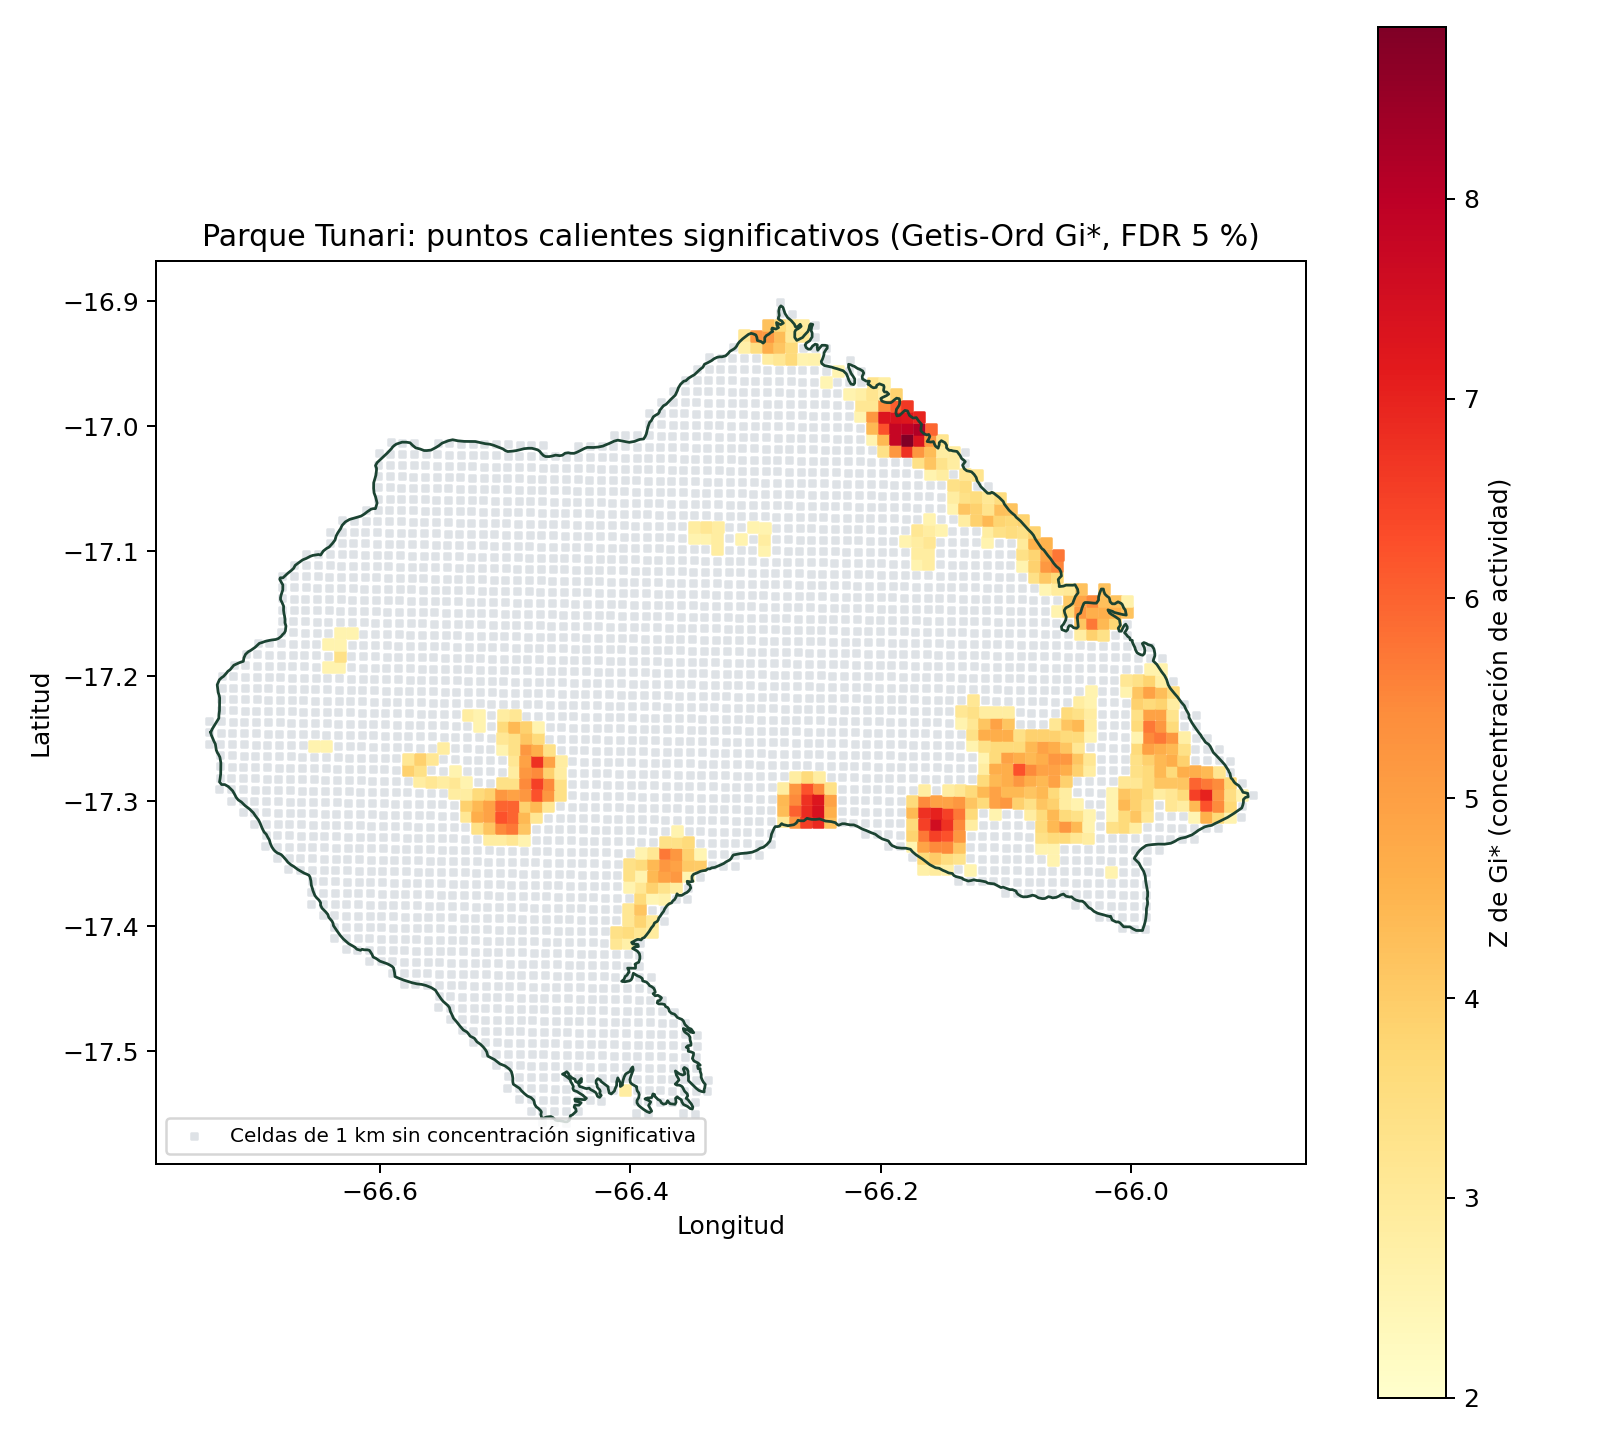

In [11]:
gi = pd.read_csv(PAQ / "puntos_calientes_gi.csv")
res = gi.groupby("area_id").agg(celdas=("cell_id", "size"), calientes=("punto_caliente", "sum"), frias=("punto_frio", "sum"))
res["% calientes"] = 100 * res.calientes / res.celdas
display(res.round(1))

for etq, col, aid in (("parque", "en_parque_tunari", "parque-tunari"), ("municipio", "en_municipio_cochabamba", "municipio-cochabamba")):
    vv = det[det[col] & (det.fuente == "VIIRS-Suomi-NPP") & det.fecha_bo.between("2013-01-01", "2025-12-31")].drop_duplicates(["cell_id", "fecha_bo"])
    fuera = int((~vv.cell_id.isin(set(gi[gi.area_id == aid].cell_id))).sum())
    verificar("9 Gi*", f"ninguna celda-día VIIRS del {etq} queda fuera de la grilla de Gi*", "det.cell_id ⊂ grilla Gi*", fuera == 0, f"{len(vv)} celdas-día, {fuera} fuera")
verificar("9 Gi*", "parque: 547 de 3 492 celdas son puntos calientes", "conteo", int(res.loc["parque-tunari", "calientes"]) == 547 and int(res.loc["parque-tunari", "celdas"]) == 3492)
verificar("9 Gi*", "toda celda de Gi* está registrada en celdas_1km", "gi.cell_id ⊂ celdas_1km", gi.cell_id.isin(set(celdas.cell_id)).all())
figura("tunari_puntos_calientes_gi.png", 750)

## 10. Pruebas de robustez (por qué solo el Tunari es mixto)

Se probó la primera versión de la regla (modo mixto con ≥ 100 celdas-día de MODIS) y se **retiró**: el umbral era arbitrario y el factor propio de otras áreas no coincide o no es estable. Resultados completos en `VERIFICACION_REGLA_DISTRITOS/pruebas/`.

In [12]:
p5 = pd.read_csv(PRU / "P5_estabilidad_factor.csv").set_index("area")
display(p5[["modis_cd", "meses_con_ambos", "f_propio", "bootstrap_anios_p5", "bootstrap_anios_p95", "ancho_rel_pct"]])
print("Lectura: el factor de Morochata (1,79) es claramente distinto de 2,87; el de Sacaba (2,46) es menor pero su intervalo alcanza 2,87 marginalmente; el del Tunari es el único estable (ancho 18 %).")
display(pd.read_csv(PRU / "P1_modo_por_umbral.csv").set_index("area_id").loc[lambda d: d.nunique(axis=1) > 1])
display(pd.read_csv(PRU / "P3_replica_noaa20.csv"))

verificar("10 Robustez", "el factor propio del Tunari es 2,87 con ancho del bootstrap de 18 %", "P5_estabilidad_factor.csv", abs(p5.loc["parque-tunari", "f_propio"] - 2.87) < 0.01 and p5.loc["parque-tunari", "ancho_rel_pct"] == 18)
verificar("10 Robustez", "el factor propio de Morochata (1,79) queda fuera del intervalo del Tunari", "P5", p5.loc["mun-morochata", "bootstrap_anios_p95"] < 2.87, f"{p5.loc['mun-morochata','bootstrap_anios_p5']}–{p5.loc['mun-morochata','bootstrap_anios_p95']}")

,modis_cd,meses_con_ambos,f_propio,bootstrap_anios_p5,bootstrap_anios_p95,ancho_rel_pct
area,,,,,,
parque-tunari,499,77,2.870,2.670,3.190,18.000
mun-morochata,127,32,1.790,1.460,2.380,51.000
mun-sacaba,105,31,2.460,2.080,2.890,33.000
mun-villa-tunari,50,23,3.100,2.780,3.620,27.000


Lectura: el factor de Morochata (1,79) es claramente distinto de 2,87; el de Sacaba (2,46) es menor pero su intervalo alcanza 2,87 marginalmente; el del Tunari es el único estable (ancho 18 %).


,25,50,75,100,125,150
area_id,,,,,,
mun-morochata,mixto,mixto,mixto,mixto,mixto,solo_viirs
mun-sacaba,mixto,mixto,mixto,mixto,solo_viirs,solo_viirs
mun-villa-tunari,mixto,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs
mun-colomi,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs
mun-cocapata,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs
mun-quillacollo,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs
municipio-cochabamba,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs
mun-tiquipaya,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs
mun-sipe-sipe,mixto,solo_viirs,solo_viirs,solo_viirs,solo_viirs,solo_viirs


,zona,suomi_cd,noaa20_cd,razon_noaa20_suomi
0,distrito-01,0,0,NaN
1,distrito-02,0,2,NaN
2,distrito-03,2,0,0.000
3,distrito-04,7,9,1.290
4,distrito-05,2,4,2.000
5,distrito-06,2,2,1.000
6,distrito-07,3,8,2.670
7,distrito-08,23,31,1.350
8,distrito-09,37,47,1.270
9,distrito-10,0,0,NaN


✔ OK    el factor propio del Tunari es 2,87 con ancho del bootstrap de 18 %
✔ OK    el factor propio de Morochata (1,79) queda fuera del intervalo del Tunari   [1.46–2.38]


## 11. Compatibilidad con el backend de TunariGuard

Hay dos caminos (detalle en `entrega_backend/docs/COMPATIBILIDAD_CON_TUNARIGUARD.md`):
- **A.** `formato_firms/`: las detecciones crudas en el formato exacto de FIRMS que su importador ya lee.
- **B.** esquema `fuego`: análisis ya calculado. **No es idéntico** a sus tablas.

Aquí se **emula** (en Python) el normalizador de su importador (`normalize-firms-record.ts`) sobre los dos CSV del camino A. Es una emulación, no su código ejecutado.

In [13]:
ALIAS = {"T": "TERRA", "TERRA": "TERRA", "A": "AQUA", "AQUA": "AQUA", "N": "SNPP", "NPP": "SNPP", "SNPP": "SNPP", "SUOMI NPP": "SNPP", "SUOMI-NPP": "SNPP",
         "N20": "NOAA20", "1": "NOAA20", "NOAA-20": "NOAA20", "NOAA20": "NOAA20", "J1": "NOAA20", "N21": "NOAA21", "2": "NOAA21", "NOAA-21": "NOAA21", "NOAA21": "NOAA21", "J2": "NOAA21"}
POR_SENSOR = {"MODIS": {"TERRA", "AQUA"}, "VIIRS": {"SNPP", "NOAA20", "NOAA21"}}

def normaliza(r):
    sensor = r["instrument"].strip().upper()
    assert sensor in POR_SENSOR
    plat = ALIAS[r["satellite"].strip().upper()]
    assert plat in POR_SENSOR[sensor]
    la, lo = float(r["latitude"]), float(r["longitude"])
    assert -90 <= la <= 90 and -180 <= lo <= 180
    assert re.fullmatch(r"\d{4}-\d{2}-\d{2}", r["acq_date"])
    t = r["acq_time"].replace(":", ""); assert re.fullmatch(r"\d{1,4}", t); t = t.zfill(4); assert int(t[:2]) <= 23 and int(t[2:]) <= 59
    conf = r["confidence"].strip(); assert conf
    assert (0 <= float(conf) <= 100) if sensor == "MODIS" else conf.lower() in ("l", "n", "h", "low", "nominal", "high")
    assert r["daynight"] in ("D", "N")
    return "|".join([sensor, plat, f"{r['acq_date']}T{t[:2]}:{t[2:]}", f"{la:.5f}", f"{lo:.5f}"])

claves, rechazadas = [], 0
for nombre in ("firms_modis_cochabamba", "firms_viirs_cochabamba"):
    d = pd.read_csv(ROOT / "entrega_backend" / "formato_firms" / f"{nombre}.csv", dtype=str, keep_default_na=False)
    for r in d.to_dict("records"):
        try: claves.append(normaliza(r))
        except Exception: rechazadas += 1
print(f"Filas del camino A: {len(claves) + rechazadas} | rechazadas por el normalizador (emulado): {rechazadas} | claves de deduplicación repetidas: {len(claves) - len(set(claves))}")

PLAT = {"Terra": "TERRA", "Aqua": "AQUA", "Suomi-NPP": "SNPP", "NOAA-20": "NOAA20", "NOAA-21": "NOAA21"}
k2 = (det.sensor + "|" + det.plataforma.map(PLAT) + "|" + pd.to_datetime(det.fecha_hora_utc).dt.strftime("%Y-%m-%dT%H:%M") + "|" + det.lat.map("{:.5f}".format) + "|" + det.lon.map("{:.5f}".format))
sub = int(k2.isin(set(claves)).sum())

verificar("11 Backend", "los 2 CSV de formato_firms (11 923 filas) pasan el normalizador de TunariGuard (emulado)", "reglas de normalize-firms-record.ts", rechazadas == 0 and len(claves) == 11923, f"{rechazadas} rechazadas")
verificar("11 Backend", "no hay claves de deduplicación repetidas en el camino A", "len(claves) == len(set(claves))", len(claves) == len(set(claves)))
verificar("11 Backend", "las 6 157 detecciones de fuego.detecciones son un subconjunto de las 11 923 del camino A", "clave (plataforma, instante UTC, lat, lon a 5 decimales)", sub == len(det) == 6157, f"{sub} de {len(det)}")

Filas del camino A: 11923 | rechazadas por el normalizador (emulado): 0 | claves de deduplicación repetidas: 0
✔ OK    los 2 CSV de formato_firms (11 923 filas) pasan el normalizador de TunariGuard (emulado)   [0 rechazadas]
✔ OK    no hay claves de deduplicación repetidas en el camino A
✔ OK    las 6 157 detecciones de fuego.detecciones son un subconjunto de las 11 923 del camino A   [6157 de 6157]


## 12. Verificación del pipeline original

Se ejecutan los dos verificadores del proyecto como procesos aparte y se guarda su salida:
`verificar_pipeline_tunari.py` (territorio, eventos, selección de modelo sin prueba, líneas base, alertas, backtest) y `verificar_regla_areas.py` (regla del índice, alertas, Gi\*, nombres).

In [14]:
r1 = correr("verificar_pipeline_tunari.py")
print(r1.stdout.strip().splitlines()[-1] if r1.stdout.strip() else r1.stderr[-400:])
verificar("12 Pipeline", "verificar_pipeline_tunari.py termina bien", "subproceso, código de salida 0 y línea «OK»", r1.returncode == 0 and "OK" in r1.stdout, r1.stdout.strip().splitlines()[-1][:90] if r1.stdout.strip() else "")

r2 = correr("verificar_regla_areas.py", "--base", str(BASE))
salida = [l for l in r2.stdout.splitlines() if l[:2] in ("A1", "A2", "A3", "A4", "B1", "B2", "B3", "B4", "B5", " D", "D.", "E.") or l.startswith("RESULTADO") or l.startswith("D.") or l.startswith("E.")]
print("\n".join(salida))
verificar("12 Pipeline", "verificar_regla_areas.py (A1–A4, B1–B5, D, E) termina en RESULTADO: OK", "subproceso, última línea", r2.returncode == 0 and r2.stdout.strip().splitlines()[-1].startswith("RESULTADO: OK"), r2.stdout.strip().splitlines()[-1])

OK: territorio, eventos/complejos, selección de modelo sin prueba, validación con dos líneas base, alertas con categorías y base VIIRS, backtest prospectivo, distritos, municipios, recurrencia por celda, municipio de Cochabamba (15 distritos), factor de armonización, puntos calientes Gi*, paquete para el backend y notebooks.
✔ OK    verificar_pipeline_tunari.py termina bien   [OK: territorio, eventos/complejos, selección de modelo sin prueba, validación con dos líne]


A1. Parque Tunari: 303 meses, 15 columnas idénticas a antes: True
A2. alertas_mensuales.csv (5207 filas): mismas filas True; probabilidad de exceso y conteos idénticos True; Tunari y municipios del parque idénticos True
A3. serie_agregada.csv idéntico a antes: True
A4. Conteos de MODIS/VIIRS, índice para alertas y base de alertas de las 31 áreas sin cambios: True
B1. metodo_indice de las 31 áreas coincide con la regla (solo parque-tunari es mixto_calibrado): True
B1b. origen_factor, validacion_local y comparabilidad_pre_2012 coherentes con el método: True
B2. viirs_reescalado antes de feb-2012: índice NULL y calidad no_comparable: True  (3906 meses)
B3. viirs_reescalado desde feb-2012: índice = VIIRS / f y calidad aproximado_factor_transferido: True  (5310 meses)
B4. rango de sensibilidad ordenado (VIIRS/3,37 <= índice <= VIIRS/2,09): True
B5. mixto_calibrado: solo Tunari y calidad calibrado_localmente_en_tunari: True
D. Gi* parque: 1683 celdas-día VIIRS 2013-2025, fuera de la grilla: 

**Verificado fuera del notebook** (porque necesita Docker/PostGIS; no se ejecuta aquí, se deja constancia):

| Qué | Cómo | Resultado (13-nov-2026) |
|---|---|---|
| El paquete completo y el zip simplificado se cargan en PostgreSQL 16 + PostGIS 3.4 | `cargar.sh --recrear`; `sql/01`, `02`, `03` (con la validación `04` dentro) | Carga limpia, esquema 2026.11.13-6 |
| La función SQL `serie_armonizada_area` reproduce `serie_mensual` | validación `04_validar_carga.sql` y consulta de control | 31 de 31 áreas |
| Novedades y alerta del mes en curso son idempotentes | `sql/05` (dos veces) y `sql/06` | Sin errores |
| Un polígono dibujado devuelve `viirs_reescalado` | `serie_armonizada_poligono` | Confirmado |

## 13. Qué se verificó (tabla completa)

In [15]:
tabla = pd.DataFrame(VERIF)
pd.set_option("display.max_colwidth", 95)
display(tabla.style.hide(axis="index"))
n_ok, n_fal = int((tabla.resultado == "OK").sum()), int((tabla.resultado == "FALLA").sum())
print(f"\nComprobaciones ejecutadas en este notebook: {len(tabla)}  |  OK: {n_ok}  |  FALLAN: {n_fal}")
assert n_fal == 0, "hay comprobaciones que fallan; revisar la tabla"

sección,qué se verifica,cómo,resultado,detalle
1 Datos,id_deteccion es único,len(unique) == len(filas),OK,6157
1 Datos,la cobertura termina el 2026-10-31 (último mes completo con Suomi-NPP),max(fecha_bo) <= 2026-10-31,OK,2026-10-31
2 Filtro,todas las filas son tipo 0,det.tipo == 0,OK,
2 Filtro,ninguna fila tiene confianza «baja»,"confianza_clase ∈ {nominal, alta}",OK,
2 Filtro,solo las filas NRT tienen tipo desconocido,tipo_conocido == False ⇔ origen_dato == NRT,OK,
3 Día,fecha_bo = fecha UTC − 4 horas en todas las filas,recalculo de (UTC − 4 h).fecha,OK,0 difieren
4 Grilla,toda detección cae en una celda registrada,det.cell_id ⊂ celdas_1km.cell_id,OK,
4 Grilla,los 17 CSV del paquete tienen el número de filas esperado,conteos_esperados.json == filas reales,OK,17 tablas
4 Grilla,la versión del esquema es 2026.11.13-6,ESQUEMA_VERSION,OK,2026.11.13-6
5 Armonización,"el factor operativo es 2,8715",tunari_factores_calibracion.csv,OK,2.8715



Comprobaciones ejecutadas en este notebook: 45  |  OK: 45  |  FALLAN: 0


## 14. Limitaciones que hay que decir

1. **El factor 2,87 está calibrado solo en el Tunari.** Fuera de él, VIIRS/2,87 es un **cambio de escala con factor transferido**, no una armonización local validada de dos sensores.
2. **No se puede validar el factor en los distritos**: MODIS casi no registra detecciones (en 2022–2025, 3 celdas-día entre los 15 distritos).
3. **Antes de febrero de 2012 la historia no es comparable** en los distritos y demás áreas.
4. **El error mensual es alto (~40 %) incluso en el Tunari**; el uso responsable es trimestral o anual.
5. **El rango 2,09–3,37 es de sensibilidad**, no un intervalo de confianza.
6. **Calendario no uniforme:** el parque y los municipios del parque empiezan en agosto de 2001; los distritos, en enero de 2001. Una fila ausente no es un cero. Para series temporales usar un rango común explícito (por ejemplo desde 2013).
7. **NOAA-21:** las páginas oficiales de FIRMS no coinciden en su fecha de inicio y hay un salto de nivel entre dic-2025 y ene-2026; está en el catálogo como detección pero **fuera del índice**.
8. **Suomi-NPP dejó de entregar datos a inicios de noviembre de 2026**; para datos nuevos se usa NOAA-20 enlazado.
9. Los resultados solo aplican **dentro de la cobertura cargada** (parque y municipio de Cochabamba, hasta el 31-oct-2026).
10. **Los límites de distritos no son oficiales** (referencia abierta); las capas del GAMC se usan para clasificar, no como geometría original.

## 15. Cómo actualizar cuando llegan datos nuevos

| Cuándo llega | Qué se corre | Quién |
|---|---|---|
| Detecciones en vivo (cada pocas horas) | La ingesta del backend (`observations`) | Backend (Adri) |
| Alerta del mes en curso | `python alerta_mes_en_curso.py` y luego `sql/06_cargar_alerta_mes_en_curso.sql` | Análisis |
| Cierre de mes o dato estándar nuevo | `python actualizar_todo.py` (incluye ambos verificadores) y cargar con `sql/03` o `05` | Análisis → backend |
| Dato estándar que reemplaza lo provisional | Reemplazar las filas NRT **por rango de fechas**, no por clave | Backend |

Después de cada actualización: **volver a ejecutar este notebook**; la sección 13 debe terminar con 0 fallas.

### Pendiente (no hecho todavía)
- **Series de tiempo anuales** (predicción del conteo anual): propuesta = regresión de conteos con covariables climáticas (balance hídrico, ONI), evaluada con validación temporal, 2026 como prueba. Se deja fuera hasta tener el calendario común con estado por mes.
- Calendario común con estado por mes (cero confirmado, sin datos, mes incompleto).